# Phase 3 — 고전 비지도 이상탐지 모델

Phase 2에서 마할라노비스 거리로 만든 통계적 베이스라인의 성적표: val macro-F1 0.7324, Public 0.6614, Private 0.6396.
특히 recall(사기를 놓치지 않고 잡아내는 능력)이 약점이었습니다 (val에서 30건 중 10건만 포착).

이 노트북에서는 scikit-learn이 제공하는 4가지 비지도 이상탐지 알고리즘을 하나씩 학습하고 구현합니다.
1. Isolation Forest
2. Local Outlier Factor (LOF)
3. One-Class SVM
4. Elliptic Envelope (Phase 2의 마할라노비스 거리와 같은 원리 + 강건한 공분산 추정)

각 모델마다 동일한 절차를 반복합니다: train으로 학습 → val 점수화 → threshold 튜닝(macro-F1 최대화) → 기록.
마지막에 Phase 2 베이스라인을 포함한 전체 비교표를 만들고, 가장 좋은 모델로 두 번째 제출을 합니다.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv('../data/train.csv')
val = pd.read_csv('../data/val.csv')
test = pd.read_csv('../data/test.csv')
feature_cols = [c for c in train.columns if c.startswith('V')]

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

y_true = val['Class'].values

print('train:', train.shape, '/ val:', val.shape, '/ test:', test.shape)

train: (113842, 31) / val: (28462, 32) / test: (142503, 31)


## 공통 함수 준비

Phase 2에서 만든 macro-F1 계산 함수와 threshold 스윕 로직을, 모델마다 반복해서 쓸 수 있도록 함수로 정리합니다.
(Phase 2 노트북에서 검증까지 마친 로직이라 여기서는 재검증 없이 그대로 재사용합니다.)

In [2]:
def confusion_counts(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp, tn, fp, fn

def precision_recall_f1(y_true, y_pred):
    tp, tn, fp, fn = confusion_counts(y_true, y_pred)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return precision, recall, f1

def macro_f1(y_true, y_pred):
    _, _, f1_class1 = precision_recall_f1(y_true, y_pred)
    _, _, f1_class0 = precision_recall_f1(1 - y_true, 1 - y_pred)
    return (f1_class0 + f1_class1) / 2, f1_class0, f1_class1

def find_best_threshold(y_true, scores, max_k=2000):
    # 점수가 높은 순으로 상위 k건을 사기로 예측하는 모든 경우(k=1~max_k)를 빠짐없이 탐색합니다
    # (사기가 극소수라 의미 있는 threshold는 상위 몇십 건 안에 몰려 있어서, 균등 간격 탐색은 놓치기 쉽습니다)
    order = np.argsort(-scores)
    sorted_y = y_true[order]
    n_pos = y_true.sum()
    n_neg = len(y_true) - n_pos
    k = np.arange(1, max_k + 1)
    tp = np.cumsum(sorted_y)[:max_k]   # 상위 k건 중 진짜 사기 수
    fp = k - tp
    fn = n_pos - tp
    tn = n_neg - fp
    # F1 = 2TP / (2TP + FP + FN): 사기 기준 F1과 정상 기준 F1을 평균내면 macro-F1
    macro = (2 * tp / (2 * tp + fp + fn) + 2 * tn / (2 * tn + fn + fp)) / 2
    best_idx = np.argmax(macro)
    thresholds = scores[order][:max_k]   # k번째로 높은 점수 = 'score >= threshold면 사기'로 예측할 때의 threshold
    return thresholds[best_idx], macro[best_idx], thresholds, macro

# 나중에 모델별 결과를 모아둘 표
results = {'마할라노비스(Phase2)': {'threshold': 48.7485, 'val_macro_f1': 0.7324}}

## 1. Isolation Forest 학습

train(라벨 없이, 대부분 정상)으로 학습시킵니다. sklearn의 score_samples()는 "높을수록 정상"인 점수를 주는데,
우리 threshold 함수는 "높을수록 이상치"인 점수를 기대하므로 부호를 뒤집어서 사용합니다.

In [3]:
from sklearn.ensemble import IsolationForest

iso_forest = IsolationForest(n_estimators=100, random_state=42, n_jobs=-1)
iso_forest.fit(train[feature_cols])

# score_samples: 높을수록 정상(inlier) -> 부호를 뒤집어서 '높을수록 이상치'로 통일
iso_scores_val = -iso_forest.score_samples(val[feature_cols])

print('val 이상치 점수 예시 (앞 5개):', iso_scores_val[:5])

val 이상치 점수 예시 (앞 5개): [0.38291032 0.45045183 0.40228642 0.42727715 0.56476234]


## 2. threshold 튜닝 및 정상/사기 점수 분포 확인

Isolation Forest 최적 threshold: 0.6876
val macro-F1: 0.6912


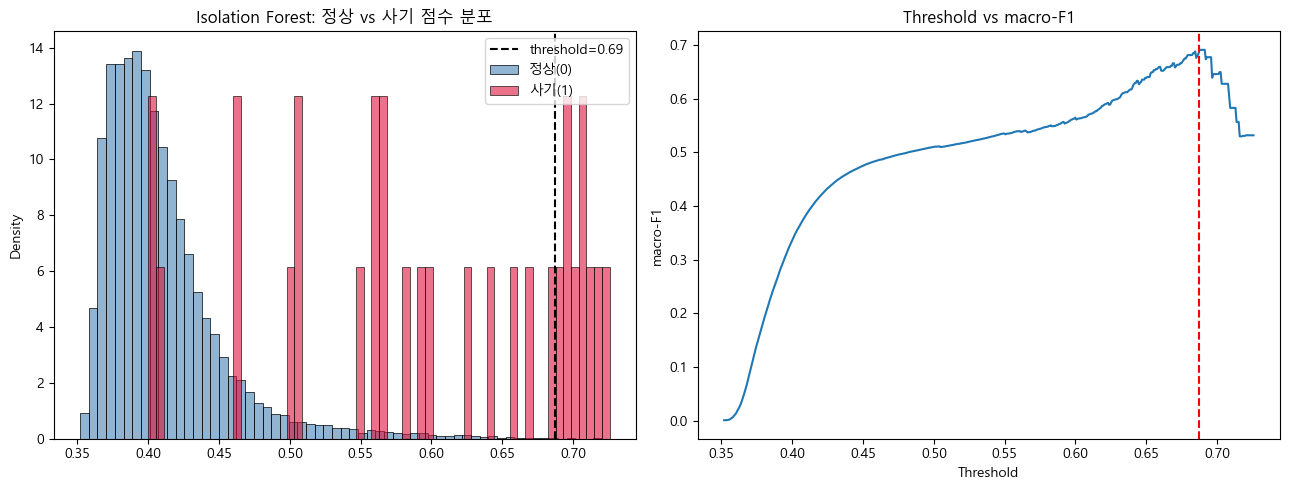

In [4]:
best_t, best_f1, thresholds, f1_curve = find_best_threshold(y_true, iso_scores_val)
results['Isolation Forest'] = {'threshold': best_t, 'val_macro_f1': best_f1}

print(f'Isolation Forest 최적 threshold: {best_t:.4f}')
print(f'val macro-F1: {best_f1:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(iso_scores_val[y_true == 0], bins=60, stat='density', label='정상(0)', color='steelblue', alpha=0.6, ax=axes[0])
sns.histplot(iso_scores_val[y_true == 1], bins=60, stat='density', label='사기(1)', color='crimson', alpha=0.6, ax=axes[0])
axes[0].axvline(best_t, color='black', linestyle='--', label=f'threshold={best_t:.2f}')
axes[0].set_title('Isolation Forest: 정상 vs 사기 점수 분포')
axes[0].legend()

axes[1].plot(thresholds, f1_curve)
axes[1].axvline(best_t, color='red', linestyle='--')
axes[1].set_title('Threshold vs macro-F1')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('macro-F1')

plt.tight_layout()
plt.show()

## 3. Local Outlier Factor (LOF) 학습

`novelty=True`로 설정해야 학습에 쓰지 않은 새 데이터(val, test)에 대해 점수를 매길 수 있습니다
(기본 모드는 학습 데이터 자체의 이상치만 찾는 용도라 val/test에는 못 씁니다).

`n_neighbors=20`: 주변 몇 개의 이웃과 밀도를 비교할지 정하는 값 (기본값, 늘리면 더 넓은 범위의 "동네"를 기준으로 삼음).

주의: train(113,842개) 전체를 대상으로 이웃을 찾아야 해서 Isolation Forest보다 시간이 좀 더 걸릴 수 있어요 (1~2분 정도 예상).

In [5]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(n_neighbors=20, novelty=True, n_jobs=-1)
lof.fit(train[feature_cols])

# score_samples: 높을수록 정상 -> 부호를 뒤집어서 '높을수록 이상치'로 통일
lof_scores_val = -lof.score_samples(val[feature_cols])

print('val 이상치 점수 예시 (앞 5개):', lof_scores_val[:5])

c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


val 이상치 점수 예시 (앞 5개): [1.82748891 1.08723916 1.20258439 0.9806143  1.03662633]


## 4. threshold 튜닝 및 정상/사기 점수 분포 확인

LOF 최적 threshold: 53.3202
val macro-F1: 0.4997


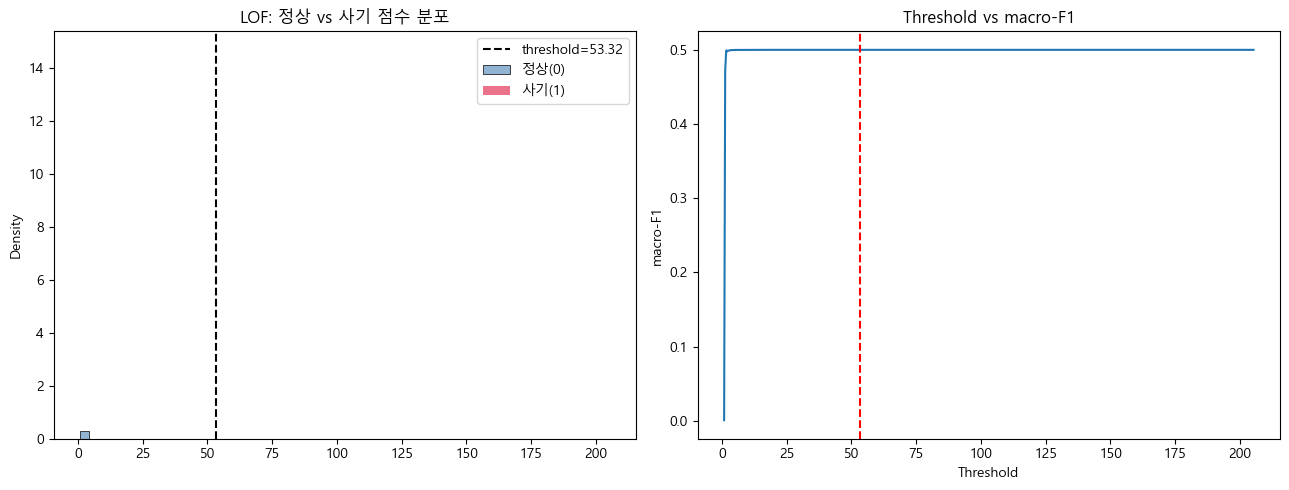

In [6]:
best_t, best_f1, thresholds, f1_curve = find_best_threshold(y_true, lof_scores_val)
results['LOF'] = {'threshold': best_t, 'val_macro_f1': best_f1}

print(f'LOF 최적 threshold: {best_t:.4f}')
print(f'val macro-F1: {best_f1:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(lof_scores_val[y_true == 0], bins=60, stat='density', label='정상(0)', color='steelblue', alpha=0.6, ax=axes[0])
sns.histplot(lof_scores_val[y_true == 1], bins=60, stat='density', label='사기(1)', color='crimson', alpha=0.6, ax=axes[0])
axes[0].axvline(best_t, color='black', linestyle='--', label=f'threshold={best_t:.2f}')
axes[0].set_title('LOF: 정상 vs 사기 점수 분포')
axes[0].legend()

axes[1].plot(thresholds, f1_curve)
axes[1].axvline(best_t, color='red', linestyle='--')
axes[1].set_title('Threshold vs macro-F1')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('macro-F1')

plt.tight_layout()
plt.show()

## 5. 스케일링 후 LOF 재시도

`StandardScaler`로 train 기준 평균 0, 표준편차 1로 맞춘 뒤 LOF를 다시 학습합니다.

(정정) 이 셀에서 threshold 후보를 "백분위 500칸"으로 바꿨던 적이 있는데, 사기가 30건뿐인 데이터에서는 의미 있는
threshold가 상위 0.1% 구간에 몰려 있어서 0.2%p 간격은 너무 성겼습니다. 그래서 그 방식은 없애고,
위 "공통 함수 준비"에 있는 정확한 탐색 함수(상위 k건을 사기로 예측하는 모든 경우를 확인)를 씁니다.

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(train[feature_cols])  # train 기준으로 평균/표준편차 계산 후 적용
X_val_scaled = scaler.transform(val[feature_cols])          # train 기준값을 val에 그대로 적용 (val로 다시 계산 X)

lof_scaled = LocalOutlierFactor(n_neighbors=20, novelty=True, n_jobs=-1)
lof_scaled.fit(X_train_scaled)

lof_scores_val_scaled = -lof_scaled.score_samples(X_val_scaled)
print('스케일링 후 val 점수 중앙값 - 정상:', np.median(lof_scores_val_scaled[y_true == 0]),
      '/ 사기:', np.median(lof_scores_val_scaled[y_true == 1]))

스케일링 후 val 점수 중앙값 - 정상: 1.0963407054106884 / 사기: 1.1337710570104136


## 6. threshold 튜닝 및 정상/사기 점수 분포 확인 (스케일링 버전)

LOF(스케일링) 최적 threshold: 2.1959
val macro-F1: 0.5016


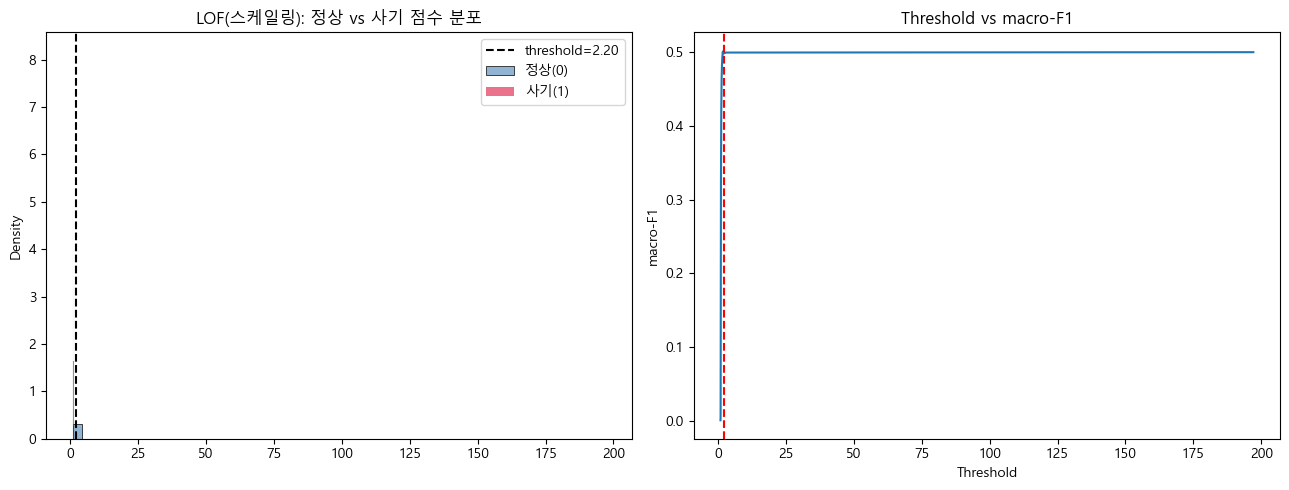

In [8]:
best_t, best_f1, thresholds, f1_curve = find_best_threshold(y_true, lof_scores_val_scaled)
results['LOF'] = {'threshold': best_t, 'val_macro_f1': best_f1}  # 스케일링 버전으로 덮어씀

print(f'LOF(스케일링) 최적 threshold: {best_t:.4f}')
print(f'val macro-F1: {best_f1:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(lof_scores_val_scaled[y_true == 0], bins=60, stat='density', label='정상(0)', color='steelblue', alpha=0.6, ax=axes[0])
sns.histplot(lof_scores_val_scaled[y_true == 1], bins=60, stat='density', label='사기(1)', color='crimson', alpha=0.6, ax=axes[0])
axes[0].axvline(best_t, color='black', linestyle='--', label=f'threshold={best_t:.2f}')
axes[0].set_title('LOF(스케일링): 정상 vs 사기 점수 분포')
axes[0].legend()

axes[1].plot(thresholds, f1_curve)
axes[1].axvline(best_t, color='red', linestyle='--')
axes[1].set_title('Threshold vs macro-F1')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('macro-F1')

plt.tight_layout()
plt.show()

## 5-보충. RobustScaler로도 LOF 시도

`RobustScaler`는 평균/표준편차 대신 **중앙값(median)과 IQR(사분위범위)**을 기준으로 스케일링합니다.
중앙값과 IQR은 극단값 몇 개에 거의 영향을 안 받기 때문에(Phase 1에서 본 V28, V29처럼 왜도·첨도가 큰
변수가 많은 데이터에서는), StandardScaler보다 이상치에 더 강건(robust)할 수 있습니다.
StandardScaler 버전과 나란히 비교해봅니다.

In [9]:
from sklearn.preprocessing import RobustScaler

robust_scaler = RobustScaler()
X_train_robust = robust_scaler.fit_transform(train[feature_cols])
X_val_robust = robust_scaler.transform(val[feature_cols])

lof_robust = LocalOutlierFactor(n_neighbors=20, novelty=True, n_jobs=-1)
lof_robust.fit(X_train_robust)

lof_scores_val_robust = -lof_robust.score_samples(X_val_robust)
print('RobustScaler 후 val 점수 중앙값 - 정상:', np.median(lof_scores_val_robust[y_true == 0]),
      '/ 사기:', np.median(lof_scores_val_robust[y_true == 1]))

RobustScaler 후 val 점수 중앙값 - 정상: 1.0896200708840085 / 사기: 1.3534166400050196


## threshold 튜닝 및 StandardScaler 버전과 비교

LOF(RobustScaler) 최적 threshold: 3.4090
val macro-F1: 0.5220
(참고) LOF(StandardScaler) val macro-F1: 0.5016


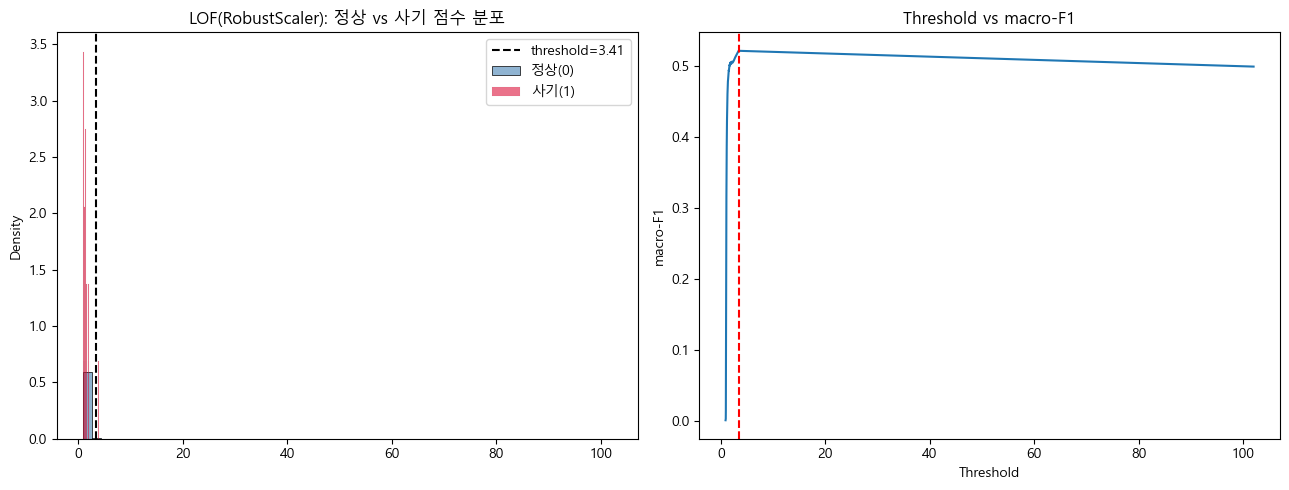

In [10]:
best_t, best_f1, thresholds, f1_curve = find_best_threshold(y_true, lof_scores_val_robust)
results['LOF (RobustScaler)'] = {'threshold': best_t, 'val_macro_f1': best_f1}

print(f'LOF(RobustScaler) 최적 threshold: {best_t:.4f}')
print(f'val macro-F1: {best_f1:.4f}')
print(f"(참고) LOF(StandardScaler) val macro-F1: {results['LOF']['val_macro_f1']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(lof_scores_val_robust[y_true == 0], bins=60, stat='density', label='정상(0)', color='steelblue', alpha=0.6, ax=axes[0])
sns.histplot(lof_scores_val_robust[y_true == 1], bins=60, stat='density', label='사기(1)', color='crimson', alpha=0.6, ax=axes[0])
axes[0].axvline(best_t, color='black', linestyle='--', label=f'threshold={best_t:.2f}')
axes[0].set_title('LOF(RobustScaler): 정상 vs 사기 점수 분포')
axes[0].legend()

axes[1].plot(thresholds, f1_curve)
axes[1].axvline(best_t, color='red', linestyle='--')
axes[1].set_title('Threshold vs macro-F1')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('macro-F1')

plt.tight_layout()
plt.show()

## 7. One-Class SVM 학습

`nu=0.01`: 정상 데이터 중 최대 1% 정도까지는 경계 밖으로 나가도 허용 (대략적인 이상치 비율 추정치, val 기준
실제 사기 비율 0.105%보다는 넉넉하게 잡았습니다 — 너무 타이트하면 학습 자체가 불안정해질 수 있어서).
`gamma='scale'`: 변수 개수와 분산을 고려해서 자동으로 적절한 값을 정해주는 sklearn 기본 옵션.

주의: One-Class SVM은 학습 데이터 크기에 민감하게 느려질 수 있어요(전체 데이터에 대해 커널 행렬을 계산하기 때문).
train 113,842개 전부로 시도해보고, 너무 오래 걸리면(5분 이상) 알려주세요 — 그러면 일부만 샘플링해서 다시 시도할게요.

In [11]:
from sklearn.svm import OneClassSVM

ocsvm = OneClassSVM(kernel='rbf', nu=0.01, gamma='scale')
ocsvm.fit(X_train_scaled)

# decision_function: 높을수록 정상(경계 안쪽) -> 부호를 뒤집어서 '높을수록 이상치'로 통일
ocsvm_scores_val = -ocsvm.decision_function(X_val_scaled)

print('val 이상치 점수 예시 (앞 5개):', ocsvm_scores_val[:5])

val 이상치 점수 예시 (앞 5개): [-2.62627085 -1.25558961 -2.10145934 -1.84058465 -0.36892008]


## 8. threshold 튜닝 및 정상/사기 점수 분포 확인

One-Class SVM 최적 threshold: 1.5920
val macro-F1: 0.6017


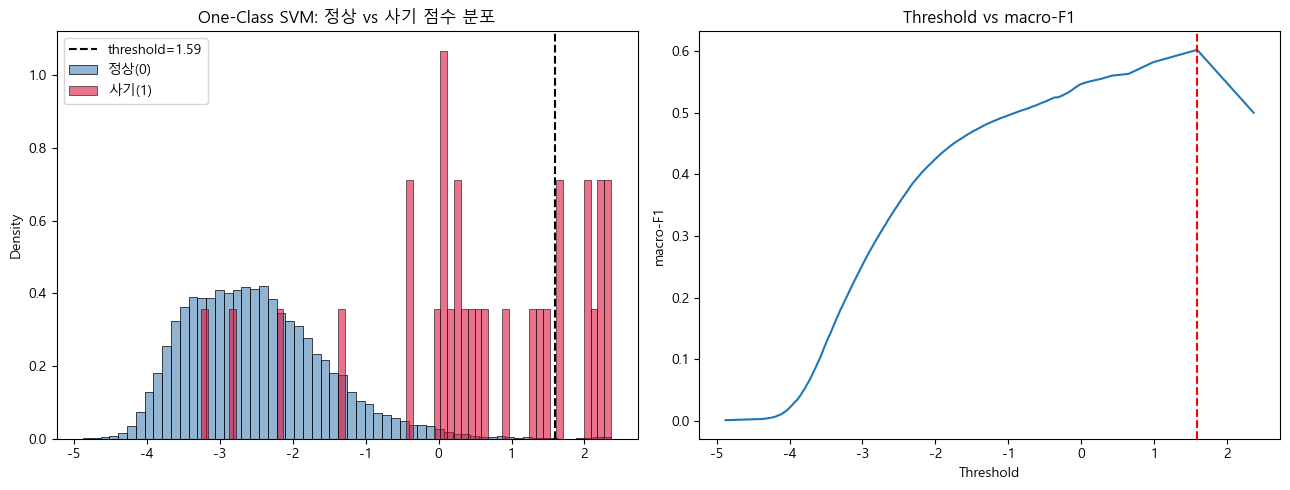

In [12]:
best_t, best_f1, thresholds, f1_curve = find_best_threshold(y_true, ocsvm_scores_val)
results['One-Class SVM'] = {'threshold': best_t, 'val_macro_f1': best_f1}

print(f'One-Class SVM 최적 threshold: {best_t:.4f}')
print(f'val macro-F1: {best_f1:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(ocsvm_scores_val[y_true == 0], bins=60, stat='density', label='정상(0)', color='steelblue', alpha=0.6, ax=axes[0])
sns.histplot(ocsvm_scores_val[y_true == 1], bins=60, stat='density', label='사기(1)', color='crimson', alpha=0.6, ax=axes[0])
axes[0].axvline(best_t, color='black', linestyle='--', label=f'threshold={best_t:.2f}')
axes[0].set_title('One-Class SVM: 정상 vs 사기 점수 분포')
axes[0].legend()

axes[1].plot(thresholds, f1_curve)
axes[1].axvline(best_t, color='red', linestyle='--')
axes[1].set_title('Threshold vs macro-F1')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('macro-F1')

plt.tight_layout()
plt.show()

## 9. Elliptic Envelope 학습

`contamination=0.001`: train 중 약 0.1%를 이상치로 간주하고, MCD 알고리즘이 그만큼을 제외한 핵심 데이터로
평균·공분산을 다시 추정합니다. 공분산 기반이라 스케일링되지 않은 원본 feature_cols를 그대로 사용합니다.

In [13]:
from sklearn.covariance import EllipticEnvelope

envelope = EllipticEnvelope(contamination=0.001, random_state=42)
envelope.fit(train[feature_cols])

# decision_function: 높을수록 정상 -> 부호를 뒤집어서 '높을수록 이상치'로 통일
envelope_scores_val = -envelope.decision_function(val[feature_cols])

print('val 이상치 점수 예시 (앞 5개):', envelope_scores_val[:5])

c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\covariance\_robust_covariance.py:185: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-243.974790944892789 > -279.760816127201963). You may want to try with a higher value of support_fraction (current value: 0.501).
  warnings.warn(
c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\covariance\_robust_covariance.py:185: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-203.230962225580470 > -311.801757234774584). You may want to try with a higher value of support_fraction (current value: 0.501).
  warnings.warn(
c:\Users\이성진\OneDrive - KookminUNIV\바탕 화면\사기거래탐지\venv\lib\site-packages\sklearn\covariance\_robust_covariance.py:185: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-221.403555963531744 > -311.230590020237116). You may want to

val 이상치 점수 예시 (앞 5개): [-1.18153327e+09 -1.18153327e+09 -1.18153328e+09 -1.18153327e+09
 -1.18150011e+09]


## 10. threshold 튜닝 및 정상/사기 점수 분포 확인

Elliptic Envelope 최적 threshold: -658901712.0097
val macro-F1: 0.5561
(참고) Phase 2 마할라노비스 val macro-F1: 0.7324


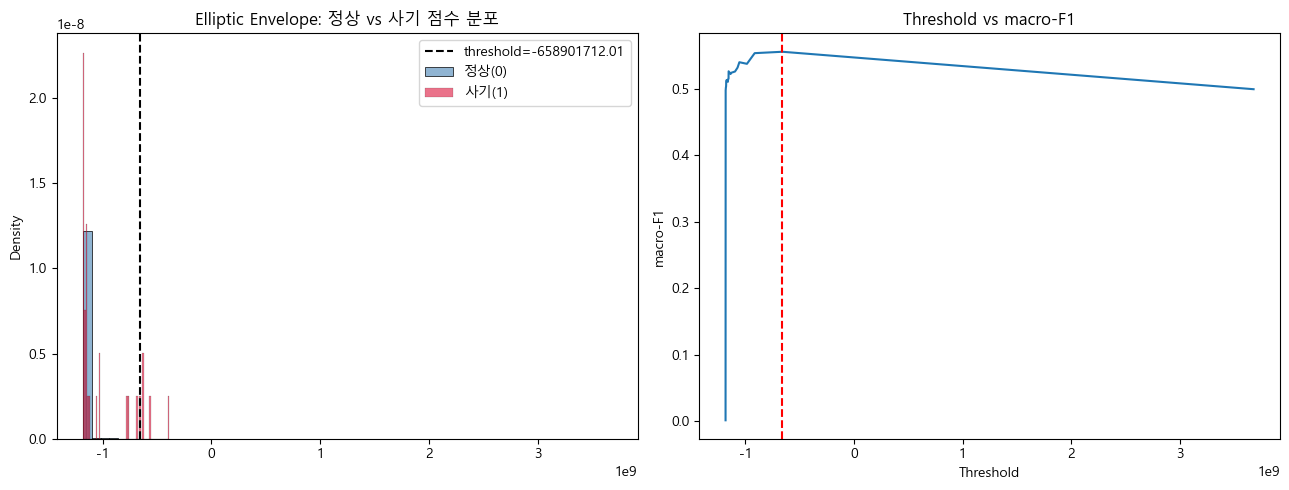

In [14]:
best_t, best_f1, thresholds, f1_curve = find_best_threshold(y_true, envelope_scores_val)
results['Elliptic Envelope'] = {'threshold': best_t, 'val_macro_f1': best_f1}

print(f'Elliptic Envelope 최적 threshold: {best_t:.4f}')
print(f'val macro-F1: {best_f1:.4f}')
print(f"(참고) Phase 2 마할라노비스 val macro-F1: {results['마할라노비스(Phase2)']['val_macro_f1']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(envelope_scores_val[y_true == 0], bins=60, stat='density', label='정상(0)', color='steelblue', alpha=0.6, ax=axes[0])
sns.histplot(envelope_scores_val[y_true == 1], bins=60, stat='density', label='사기(1)', color='crimson', alpha=0.6, ax=axes[0])
axes[0].axvline(best_t, color='black', linestyle='--', label=f'threshold={best_t:.2f}')
axes[0].set_title('Elliptic Envelope: 정상 vs 사기 점수 분포')
axes[0].legend()

axes[1].plot(thresholds, f1_curve)
axes[1].axvline(best_t, color='red', linestyle='--')
axes[1].set_title('Threshold vs macro-F1')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('macro-F1')

plt.tight_layout()
plt.show()

## 10-보충 1. threshold 탐색 함수 정정 및 재평가

Dacon 베이스라인과 비교하다가 threshold 후보를 "백분위 500칸"으로 잡은 방식이 너무 성기다는 걸 발견했습니다.
사기가 30건뿐이라 의미 있는 threshold는 점수 상위 몇십 건 안에 몰려 있는데, 0.2%p 간격이면 그 안에 후보가 1~2개뿐이라
진짜 최적점을 지나쳐버립니다 (예: 같은 마할라노비스 점수가 0.7324가 아니라 0.6586으로 나옴).

"공통 함수 준비"의 `find_best_threshold`를 상위 k건 전수 탐색 방식으로 고쳤습니다. 먼저 옛 방식으로 검증했던
Phase 2 마할라노비스 점수(0.7324)를 새 함수가 그대로 재현하는지 확인하고, 이미 계산해둔 각 모델의 점수를 다시 평가합니다.

(먼저 "공통 함수 준비" 셀을 다시 실행해서 새 함수를 반영한 뒤 아래 셀을 실행하세요.)

In [ ]:
# 1) 새 함수 검증: Phase 2의 마할라노비스 점수를 다시 만들어서, 옛 결과(0.7324)와 같은지 확인합니다
X_tr = train[feature_cols].values
mu = X_tr.mean(axis=0)
cov_inv = np.linalg.inv(np.cov(X_tr, rowvar=False))
diff = val[feature_cols].values - mu
maha_val = np.sqrt(np.sum((diff @ cov_inv) * diff, axis=1))

t, f1, _, _ = find_best_threshold(y_true, maha_val)
check = macro_f1(y_true, (maha_val >= t).astype(int))[0]   # 우리가 직접 만든 macro_f1로 같은 threshold를 다시 계산
print(f'마할라노비스: 새 함수 최적 macro-F1={f1:.4f} / 직접 만든 macro_f1로 재계산={check:.4f} (Phase 2 결과 0.7324와 같아야 함)')

# 2) 이미 계산해둔 각 모델의 val 점수를 새 함수로 다시 평가합니다
targets = [
    ('Isolation Forest', 'iso_scores_val'),
    ('LOF', 'lof_scores_val_scaled'),                # results의 'LOF'는 StandardScaler 버전
    ('LOF (RobustScaler)', 'lof_scores_val_robust'),
    ('One-Class SVM', 'ocsvm_scores_val'),
]
for name, var in targets:
    if var in globals():
        t, f1, _, _ = find_best_threshold(y_true, globals()[var])
        old = results[name]['val_macro_f1'] if name in results else None
        old_txt = f'{old:.4f}' if old is not None else '-'
        results[name] = {'threshold': t, 'val_macro_f1': f1}
        print(f'{name}: 이전 {old_txt} -> 정정 후 {f1:.4f}')
    else:
        print(f'{name}: 점수 변수({var})가 없어요. 해당 모델 학습 셀을 다시 실행한 뒤 이 셀을 실행하세요.')

## 10-보충 2. Dacon 베이스라인 설정으로 Isolation Forest 재도전

베이스라인과 우리 설정의 가장 큰 차이는 두 가지입니다.
- `max_samples=len(train)`: 나무 한 그루가 train 전체를 봄 (우리는 기본값 256개만 봤음)
- threshold: val의 사기 비율(`contamination`)만 빌려와서 "train 점수 상위 0.1%를 사기로" 정함 (우리는 val 정답으로 최적점을 탐색)

같은 모델로 두 가지 threshold 방식을 모두 평가해서 비교합니다. 학습에 1~2분 걸릴 수 있습니다.

In [ ]:
# 베이스라인과 같은 가정: val의 사기 비율이 train/test에서도 비슷하다
val_contamination = (y_true == 1).sum() / (y_true == 0).sum()

iso_baseline = IsolationForest(n_estimators=125, max_samples=len(train), contamination=val_contamination,
                               random_state=42, n_jobs=-1)
iso_baseline.fit(train[feature_cols])

# (a) 베이스라인 방식: contamination으로 자동 결정된 threshold (predict의 -1이 이상치)
pred_fixed = (iso_baseline.predict(val[feature_cols]) == -1).astype(int)
f1_fixed = macro_f1(y_true, pred_fixed)[0]
print(f'베이스라인 방식(contamination threshold): val macro-F1={f1_fixed:.4f}, 사기로 예측한 수={pred_fixed.sum()}건')

# (b) 우리 방식: 점수를 뽑아서 val 정답으로 최적 threshold 탐색
iso_baseline_scores_val = -iso_baseline.score_samples(val[feature_cols])
best_t, best_f1, thresholds, f1_curve = find_best_threshold(y_true, iso_baseline_scores_val)
n_best = (iso_baseline_scores_val >= best_t).sum()
print(f'우리 방식(val 최적 threshold): val macro-F1={best_f1:.4f}, 사기로 예측한 수={n_best}건')

results['Isolation Forest (베이스라인 설정)'] = {'threshold': best_t, 'val_macro_f1': best_f1}

# 사기로 예측하는 건수(k)에 따라 macro-F1이 얼마나 출렁이는지 확인 (표본이 30건뿐이라 뾰족하게 흔들림)
k_axis = np.arange(1, len(f1_curve) + 1)
plt.figure(figsize=(9, 4))
plt.plot(k_axis[:100], f1_curve[:100])
plt.axvline(pred_fixed.sum(), color='gray', linestyle='--', label=f'베이스라인 방식 ({pred_fixed.sum()}건)')
plt.axvline(n_best, color='red', linestyle='--', label=f'val 최적 ({n_best}건)')
plt.xlabel('사기로 예측한 건수 (점수 상위 k건)')
plt.ylabel('val macro-F1')
plt.title('Isolation Forest(베이스라인 설정): 예측 건수별 macro-F1')
plt.legend()
plt.show()

## 10-보충 3. threshold에 흔들리지 않는 지표: PR-AUC, ROC-AUC

사기가 30건뿐이라 macro-F1은 threshold를 조금만 옮겨도 크게 출렁입니다 (위 그래프처럼). 그래서 모델의 "순위 매기는 능력"
자체를 threshold 없이 재는 지표를 같이 봅니다.
- **PR-AUC** (average precision): 점수 순서대로 잘랐을 때 precision-recall 곡선 아래 면적. 사기가 극소수일 때 가장 믿을 만한 지표
- **ROC-AUC**: 무작위로 뽑은 사기/정상 한 쌍에서 사기 점수가 더 높을 확률. 불균형이 심하면 값이 후하게 나오는 경향이 있음

In [ ]:
from sklearn.metrics import average_precision_score, roc_auc_score

all_scores = {
    '마할라노비스': maha_val,
    'Isolation Forest (베이스라인 설정)': iso_baseline_scores_val,
}
for name, var in [('Isolation Forest (우리 설정)', 'iso_scores_val'), ('LOF (StandardScaler)', 'lof_scores_val_scaled'),
                  ('LOF (RobustScaler)', 'lof_scores_val_robust'), ('One-Class SVM', 'ocsvm_scores_val')]:
    if var in globals():
        all_scores[name] = globals()[var]

rows = []
for name, s in all_scores.items():
    rows.append({
        '모델': name,
        '최적 macro-F1': find_best_threshold(y_true, s)[1],
        'PR-AUC': average_precision_score(y_true, s),
        'ROC-AUC': roc_auc_score(y_true, s),
    })
metrics_df = pd.DataFrame(rows).sort_values('PR-AUC', ascending=False).reset_index(drop=True)
display(metrics_df.round(4))

## 10-보충 4. 제출 파일 생성 (베이스라인 방식 threshold)

Phase 2에서는 val 정답으로 최적 threshold를 찾아 제출했고 Public 0.6614 / Private 0.6396이 나왔습니다.
이번에는 반대로 val 정답에 맞추지 않고 사전 비율(contamination)로 threshold를 정한 예측을 제출해서,
어느 쪽 threshold가 test에서 덜 무너지는지 비교합니다.

In [ ]:
test_pred = (iso_baseline.predict(test[feature_cols]) == -1).astype(int)   # contamination으로 정해진 threshold 사용
print('test 사기 예측 건수:', test_pred.sum(), f'({test_pred.mean() * 100:.3f}%)')

submission = pd.DataFrame({'ID': test['ID'], 'Class': test_pred})
display(submission.head())

submission.to_csv('../submissions/submission_phase3_iforest_baseline.csv', index=False)
print('저장 완료: submissions/submission_phase3_iforest_baseline.csv')

## 11. 전체 모델 비교

Phase 2 베이스라인과 Phase 3에서 시도한 4가지 비지도 이상탐지 모델의 val macro-F1을 한눈에 비교합니다.
(Elliptic Envelope는 수치적 불안정으로 실패해서 제외합니다.)

,모델,val_macro_f1
0,마할라노비스(Phase2),0.732400
1,Isolation Forest,0.691234
2,One-Class SVM,0.601657
3,LOF (RobustScaler),0.521988
4,LOF,0.501593


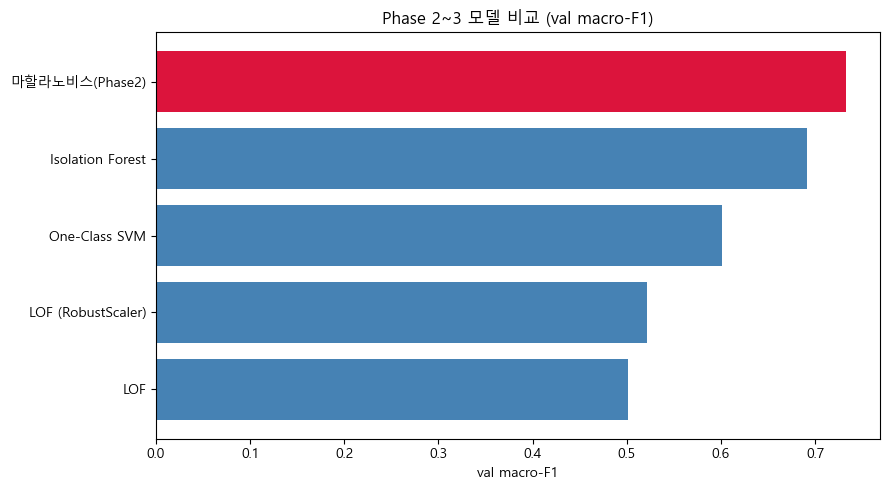

In [15]:
comparison = pd.DataFrame([
    {'모델': name, 'val_macro_f1': info['val_macro_f1']}
    for name, info in results.items() if name != 'Elliptic Envelope'
]).sort_values('val_macro_f1', ascending=False).reset_index(drop=True)

display(comparison)

plt.figure(figsize=(9, 5))
colors = ['crimson' if v == comparison['val_macro_f1'].max() else 'steelblue' for v in comparison['val_macro_f1']]
plt.barh(comparison['모델'], comparison['val_macro_f1'], color=colors)
plt.xlabel('val macro-F1')
plt.title('Phase 2~3 모델 비교 (val macro-F1)')
plt.gca().invert_yaxis()  # 표와 같은 순서로(1등이 위로) 보이게
plt.tight_layout()
plt.show()

## 12. Phase 3 요약 (최종, threshold 함수 정정 및 베이스라인 비교 반영)

**최종 비교표 (val 기준)**

| 모델 | 최적 macro-F1 | PR-AUC | ROC-AUC |
|---|---|---|---|
| **Isolation Forest (베이스라인 설정)** | **0.7379** | **0.3938** | **0.9619** |
| 마할라노비스 (Phase 2) | 0.7324 | 0.3161 | 0.9466 |
| Isolation Forest (우리 설정, max_samples=256) | 0.6912 | 0.2339 | 0.9416 |
| One-Class SVM | 0.6092 | 0.1050 | 0.9343 |
| LOF (RobustScaler) | 0.5223 | 0.0068 | 0.7508 |
| LOF (StandardScaler) | 0.5021 | 0.0020 | 0.5687 |
| Elliptic Envelope | 실패 (수치 불안정) | - | - |

**리더보드 제출 비교**

| 제출 | val macro-F1 | Public | Private | test 사기 예측 |
|---|---|---|---|---|
| 마할라노비스 + val 최적 threshold (Phase 2) | 0.7324 | 0.6614 | 0.6396 | 111건 |
| Isolation Forest(베이스라인 설정) + contamination threshold | 0.7031 | **0.6861** | **0.6877** | 198건 |

**배운 것**
1. **threshold 탐색은 "상위 k건 전수 탐색"이 정답에 가깝다** — 사기가 30건뿐이라 의미 있는 threshold는 점수 상위 몇십 건 안에 몰려 있음.
   백분위 500칸(0.2%p 간격)은 너무 성겨서 놓칠 수 있음 (다행히 이번엔 순위는 거의 안 바뀌었음).
2. **Isolation Forest의 max_samples: 기본값(256)보다 train 전체를 쓰는 게 이 데이터에선 확실히 나았음** — 사기가 0.1%대라
   256개 샘플에는 사기가 거의 없어서, 정상 영역의 경계를 충분히 촘촘하게 못 나눈 것으로 추정 (가설).
3. **val에 맞춰 threshold를 튜닝하면 과적합** — val macro-F1은 마할라노비스가 더 높았지만(0.7324 vs 0.7031),
   리더보드는 contamination 방식 IF가 더 높았음. val→리더보드 하락폭: 마할라노비스 0.07~0.09, IF(contamination) 0.015.
   다만 이 비교는 모델과 threshold 방식이 동시에 바뀌어서, 둘 중 뭐가 더 효과였는지는 분리되지 않음.
4. **불균형 데이터에서 ROC-AUC는 속일 수 있다** — LOF(RobustScaler)는 ROC-AUC 0.75로 괜찮아 보이지만 PR-AUC는 0.0068로
   사실상 무용지물. 사기가 0.1%뿐일 땐 PR-AUC가 더 정직한 지표.
5. 거리/밀도 기반(LOF, One-Class SVM)은 스케일링 필수, 그래도 LOF는 이 데이터의 "전역적 이상치" 패턴과 안 맞음.
6. Elliptic Envelope(MCD)는 이 데이터에서 수치적으로 수렴 실패 — 알고리즘 한계로 기록.

**다음 단계 (Phase 4)**: 오토인코더. 앞으로는 val 최적 threshold 하나만 보지 않고, contamination 방식 threshold와
PR-AUC를 함께 보고하는 걸 기본으로 삼습니다.